<div style="
    background: linear-gradient(90deg,
        #0F172A 0%,
        #1E3A5F 45%,
        #0F766E 100%);
    color: white;
    text-align: center;
    padding: 22px 28px;
    border-radius: 14px;
    font-family: 'Segoe UI', Arial, sans-serif;
    box-shadow: 0 6px 18px rgba(15, 23, 42, 0.25);
    border: 1px solid rgba(255,255,255,0.12);
">

<div style="
    font-size: 34px;
    font-weight: 700;
    letter-spacing: 0.8px;
    margin-bottom: 8px;">
⛏️ ROGII Wellbore Geology
</div>

<div style="
    font-size: 20px;
    font-weight: 400;
    opacity: 0.95;">
Exact HMM Smoother &nbsp;•&nbsp; Multi-Cut Validation Harness
</div>

</div>

<hr>

1. **A second-order HMM forward–backward smoother** over the joint state *(TVT, dip-rate)*. It is the exact, deterministic version of what the 128-seed likelihood-weighted particle filter approximates by Monte Carlo — and it also returns the **exact posterior variance** at every evaluation row, which the PF cannot.
2. **A multi-cut backtesting harness** that creates synthetic prediction starts inside the known prefix of every train well. This is the honest offline testbed for retuning every constant currently tuned on the public LB (selector variants, blend weights, PP params) — the biggest private-LB risk in the current pipeline.
3. **Validated evidence** (on the sample wells) that the smoother is *complementary* to the lik-PF: pooled RMSE on 5 sample wells was **PF 4.90 / HMM 5.18 / 50-50 blend 4.57** — the blend beats both components, and the HMM's posterior std correlates with |error| up to **0.92** on individual wells.

**Why this matters for the metric.** The target is pooled RMSE over ~200 test wells. RMSE is minimized by the *posterior mean* of TVT given all evidence — not by the best single trajectory (Viterbi/beam) and not by a forward-only filter estimate. Every tracker in the public baseline is forward-only or greedy; the smoother conditions each row on the *entire* GR log, past **and future**.

## 1. The generative model (why this is a tracking problem, not tabular ML)

Define the **structural offset** $U(\text{md}) = \text{TVT}(\text{md}) + Z(\text{md})$.

- $U$ is the vertical offset between the borehole and the stratigraphic column. Because formation dip changes slowly, $U$ is a **smooth** function of measured depth — its derivative (the local dip-rate, ft per ft of MD) drifts slowly, except at faults.
- The gamma-ray log ties the borehole to the column: $\text{GR}_h(\text{md}) \approx a\cdot \text{GR}_{tw}(\text{TVT}(\text{md})) + b + \varepsilon$, where $\text{GR}_{tw}$ is the typewell signature and $(a,b)$ is a per-well affine calibration.
- The known prefix (`TVT_input`) pins the state exactly at the prediction start.

So the problem is: **latent smooth path, nonlinear emission through the typewell, exact initial condition** — a textbook state-space smoothing problem. Two facts we measured on the sample wells drive the design:

| Finding | Consequence |
|---|---|
| per-foot dU is tiny (σ ≈ 0.01–0.12 ft) but **cumulative dU trends 100–170 ft** over an eval zone | dU is strongly serially correlated → we need **second-order dynamics** (a dip-rate state). A first-order random walk scored 13.0 pooled; adding the rate state with OU dynamics took it to 5.2. |
| GR residuals at the *true* TVT have an integrated autocorrelation length of **~20 ft** | iid emissions over-count evidence ~20×; the posterior can confidently commit to a wrong branch. The PF's large σ_GR (clip 10–60) implicitly compensates; we keep the same σ convention. |

## 2. Setup



In [5]:
%matplotlib inline
import os, glob, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit, prange
warnings.filterwarnings("ignore")

class CFG:
    # ---- data location: Kaggle competition mount, else local folder with the CSVs
    _cands = ["/kaggle/input/competitions/rogii-wellbore-geology-prediction",
              "/kaggle/input/rogii-wellbore-geology-prediction"]
    DATA = None
    for _c in _cands:
        if Path(_c).exists() and (Path(_c) / "train").exists():
            DATA = Path(_c) / "train"; break
    if DATA is None:
        for _p in glob.glob("/kaggle/input/**/train/*__horizontal_well.csv", recursive=True):
            DATA = Path(_p).parent; break
    if DATA is None:
        DATA = Path(os.environ.get("ROGII_DATA", "."))   # local: folder containing the per-well CSVs

    FAST = bool(int(os.environ.get("FAST", "0")))        # smoke-test mode
    N_WELLS = int(os.environ.get("N_WELLS", "0"))        # 0 = all wells found (cap for demo below)
    DEMO_MAX_WELLS = 12                                   # cap for the comparison section
    # HMM defaults (validated on sample wells; retune on the full harness!)
    HMM = dict(step=0.35, n_rates=41, rate_span=0.10, sig_r=0.002, sig_p=0.02,
               mom=0.998, lam=1.0, emission="gauss", sigma_mode="std")

def well_ids(data_dir):
    return sorted(Path(p).stem.replace("__horizontal_well", "")
                  for p in glob.glob(str(Path(data_dir) / "*__horizontal_well.csv"))
                  if (Path(data_dir) / (Path(p).stem.replace("__horizontal_well", "") + "__typewell.csv")).exists())

print("DATA:", CFG.DATA)
WIDS = well_ids(CFG.DATA)
print(f"wells with both files: {len(WIDS)}")

DATA: /kaggle/input/competitions/rogii-wellbore-geology-prediction/train
wells with both files: 773


In [6]:
def load_well(wid, data_dir):
    data_dir = Path(data_dir)
    hw = pd.read_csv(data_dir / f"{wid}__horizontal_well.csv")
    tw = pd.read_csv(data_dir / f"{wid}__typewell.csv").sort_values("TVT").reset_index(drop=True)
    return hw, tw

def rmse(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    return float(np.sqrt(np.mean((a - b) ** 2)))

def prefix_stats(hw, tw_tvt, tw_gr, tail_n=30):
    """Affine GR calibration a,b (gr_h ~ a*gr_tw + b), residual sigma, tail U-rate."""
    kn = hw[hw["TVT_input"].notna()]
    kgr = kn["GR"].to_numpy(float)
    ktvt = kn["TVT_input"].to_numpy(float)
    tw_at_k = np.interp(ktvt, tw_tvt, tw_gr)
    v = np.isfinite(kgr) & np.isfinite(tw_at_k)
    if v.sum() >= 20 and np.std(tw_at_k[v]) > 1e-6:
        a, b = np.polyfit(tw_at_k[v], kgr[v], 1)
    else:
        a, b = 1.0, float(np.nanmean(kgr) - np.nanmean(tw_at_k)) if v.any() else 0.0
    res = kgr[v] - (a * tw_at_k[v] + b)
    sig = float(np.clip(1.4826 * np.median(np.abs(res - np.median(res))), 8.0, 60.0)) if v.sum() > 20 else 30.0
    # tail U-rate (dU/dMD) like the PF's ir
    tail = kn.tail(tail_n)
    dt = np.diff(tail["TVT_input"].values); dz = np.diff(tail["Z"].values); dm = np.diff(tail["MD"].values)
    m = dm > 0
    ir = float(np.median((dt + dz)[m] / dm[m])) if m.sum() >= 3 else 0.0
    return float(a), float(b), sig, ir

## 3. A look at one well

Top: trajectory. Middle: GR (blue = known prefix, orange = eval zone). Bottom: the target — TVT, with the hidden part in red. Right: the typewell signature GR(TVT) that the tracker matches against.

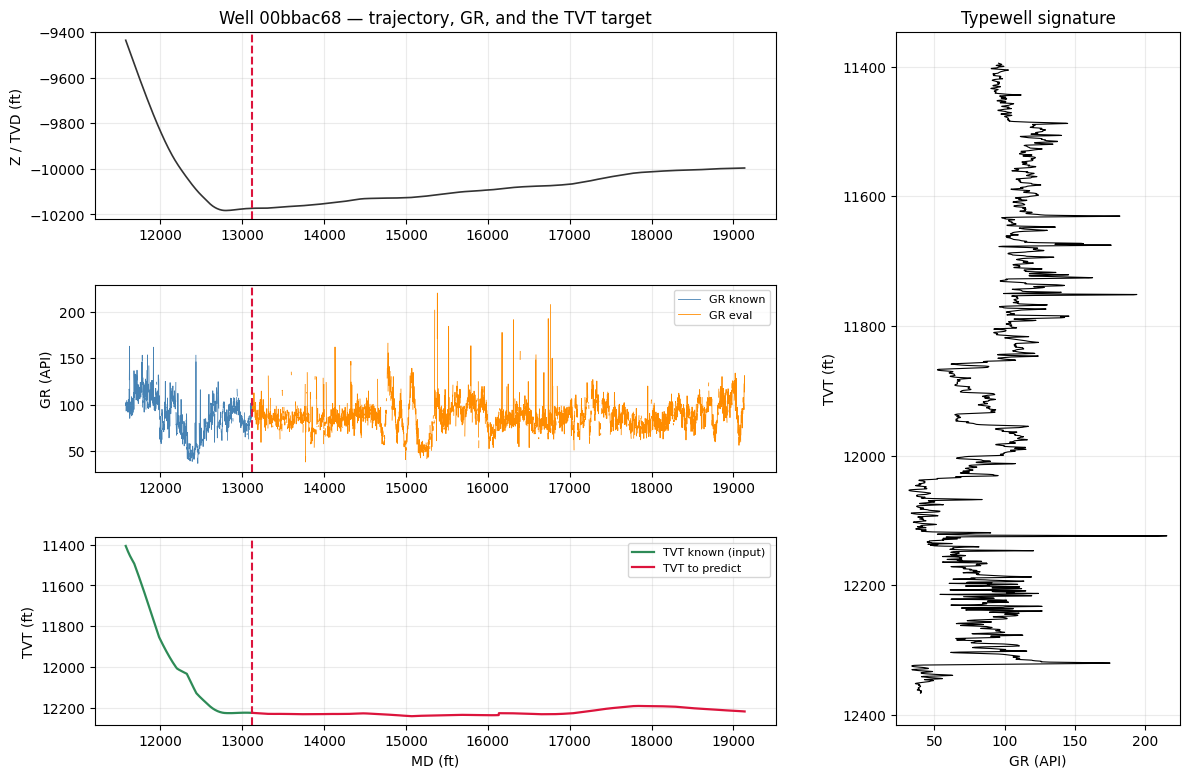

In [7]:
DEMO = WIDS[1] if len(WIDS) > 1 else WIDS[0]
hw_demo, tw_demo = load_well(DEMO, CFG.DATA)
kn = hw_demo[hw_demo.TVT_input.notna()]; ev = hw_demo[hw_demo.TVT_input.isna()]
ps = kn.MD.iloc[-1]

fig = plt.figure(figsize=(14, 9))
gs_ = fig.add_gridspec(3, 2, width_ratios=[2.4, 1], hspace=0.35, wspace=0.25)
ax0 = fig.add_subplot(gs_[0, 0]); ax1 = fig.add_subplot(gs_[1, 0], sharex=ax0); ax2 = fig.add_subplot(gs_[2, 0], sharex=ax0)
axr = fig.add_subplot(gs_[:, 1])

ax0.plot(hw_demo.MD, hw_demo.Z, lw=1.2, color="#333"); ax0.axvline(ps, color="crimson", ls="--")
ax0.set_ylabel("Z / TVD (ft)"); ax0.set_title(f"Well {DEMO} — trajectory, GR, and the TVT target")
ax1.plot(kn.MD, kn.GR, lw=.6, color="steelblue", label="GR known")
ax1.plot(ev.MD, ev.GR, lw=.6, color="darkorange", label="GR eval"); ax1.axvline(ps, color="crimson", ls="--")
ax1.set_ylabel("GR (API)"); ax1.legend(loc="upper right", fontsize=8)
ax2.plot(kn.MD, kn.TVT_input, lw=1.6, color="seagreen", label="TVT known (input)")
ax2.plot(ev.MD, ev.TVT, lw=1.6, color="crimson", label="TVT to predict"); ax2.axvline(ps, color="crimson", ls="--")
ax2.set_ylabel("TVT (ft)"); ax2.set_xlabel("MD (ft)"); ax2.invert_yaxis(); ax2.legend(loc="upper right", fontsize=8)
axr.plot(tw_demo.GR, tw_demo.TVT, lw=.8, color="black")
axr.set_xlabel("GR (API)"); axr.set_ylabel("TVT (ft)"); axr.invert_yaxis()
axr.set_title("Typewell signature")
for a in (ax0, ax1, ax2, axr): a.grid(alpha=.25)
plt.show()

## 4. The second-order HMM smoother

**State.** $(p, r)$: $p$ indexes a TVT grid (default 0.35 ft — resolution matters, see design notes), $r$ indexes a dip-rate grid (dU/dMD, 41 bins spanning ±0.10 ft/ft).

**Dynamics** (deliberately matched to the public PF's, which are well-validated):
- rate: an Ornstein–Uhlenbeck process — `r' = mom·r + noise` with `mom = 0.998`, per-step noise `sig_r = 0.002` → equilibrium rate std ≈ 0.032 ft/ft with a ~500 ft memory. On the grid this becomes a drift-plus-diffusion transition kernel with **diffusion-matched move probabilities** `p(±1) = ½(σ/Δr)²` — *not* a Gaussian kernel over grid offsets, which effectively freezes the rate when the grid step exceeds the per-step noise (a bug worth calling out: it cost 5 ft of RMSE before we caught it).
- position: `ΔTVT = r·Δmd − ΔZ + tiny noise`. ΔZ is known from the trajectory, so trajectory undulations are handled exactly.

**Emission.** Gaussian on `GR_h − GR_tw(TVT)` with σ estimated from the known prefix (clipped to [10, 60], same convention as the PF). A Student-t option and an emission-tempering knob `lam` are exposed for harness tuning.

**Inference.** Exact banded forward–backward in log space. The α lattice is `(T × P × R)` float32; the backward pass streams and emits only the **position-marginal posterior** `(T × P)`, from which we take the mean (the RMSE-optimal point estimate) and std (calibrated uncertainty, free).

**Cost.** ~T·P·R·8 ops ≈ 0.5–1 G-ops per well → seconds per well with numba (`parallel=True` uses all cores on Kaggle). Deterministic — no seeds, no Monte Carlo variance.

In [8]:
# ------------------------------------------------------------------ 2nd-order HMM (TVT x dip-rate)
@njit(cache=True, nogil=True, parallel=True)
def _hmm2_fb(em, dm, dz, sp, rates, sig_r, sig_p, start_p, start_sig,
             r0, r0_sig, lam, mom):
    """Forward-backward over joint state (position p, rate r).
    em: (T,P) emission loglik. rates: (R,) dU/dMD grid.
    Returns post_p (T,P) marginal posterior over position, loglik."""
    T, P = em.shape
    R = len(rates)
    sr = rates[1] - rates[0]
    NEG = np.float32(-1e18)
    alpha = np.full((T, P, R), NEG, np.float32)

    # ---- init distribution over (p, r)
    prev = np.full((P, R), NEG, np.float32)
    for p in range(P):
        dpos = (p - start_p) * sp
        lp0 = -0.5 * (dpos / start_sig) ** 2
        if lp0 < -60.0:
            continue
        for r in range(R):
            dr = (rates[r] - r0) / r0_sig
            prev[p, r] = np.float32(lp0 - 0.5 * dr * dr)

    tmp = np.empty((P, R), np.float32)
    cur = np.empty((P, R), np.float32)

    for t in range(T):
        sgr = sig_r * np.sqrt(dm[t])
        v_r = (sgr / sr) ** 2               # rate diffusion variance in cells^2
        # OU rate kernel per source rate r: mean drift toward 0 by (1-mom)*rate*dm
        lrk = np.empty((R, 3))
        for r in range(R):
            m_r = -(1.0 - mom) * rates[r] * dm[t] / sr   # mean move in cells
            pp = 0.5 * (v_r + m_r)
            pm = 0.5 * (v_r - m_r)
            if pp < 1e-12: pp = 1e-12
            if pm < 1e-12: pm = 1e-12
            tot = pp + pm
            if tot > 0.9:
                pp *= 0.9 / tot; pm *= 0.9 / tot
            lrk[r, 0] = np.log(pm); lrk[r, 1] = np.log(1.0 - pp - pm); lrk[r, 2] = np.log(pp)
        # step 1: mix rates
        for p in prange(P):
            for r2 in range(R):
                m2 = NEG
                k0 = r2 - 1 if r2 - 1 >= 0 else 0
                k1 = r2 + 1 if r2 + 1 <= R - 1 else R - 1
                for r in range(k0, k1 + 1):
                    v = prev[p, r] + lrk[r, r2 - r + 1]
                    if v > m2: m2 = v
                if m2 > NEG / 2:
                    ss = 0.0
                    for r in range(k0, k1 + 1):
                        ss += np.exp(prev[p, r] + lrk[r, r2 - r + 1] - m2)
                    tmp[p, r2] = np.float32(m2 + np.log(ss))
                else:
                    tmp[p, r2] = NEG
        # step 2: position shift conditioned on rate
        spe = sig_p if sig_p > 0.35 * sp else 0.35 * sp
        for r2 in range(R):
            mu = rates[r2] * dm[t] - dz[t]          # expected dTVT (ft)
            b0 = int(np.floor(mu / sp + 0.5))       # nearest cell shift
            # kernel over d in {b0-2..b0+2}
            lp = np.empty(5)
            for k in range(5):
                d = (b0 - 2 + k) * sp - mu
                lp[k] = -0.5 * (d / spe) ** 2
            mx = lp[0]
            for k in range(1, 5):
                if lp[k] > mx: mx = lp[k]
            s = 0.0
            for k in range(5): s += np.exp(lp[k] - mx)
            lz = mx + np.log(s)
            for k in range(5): lp[k] -= lz
            for p2 in prange(P):
                m2 = NEG
                for k in range(5):
                    p1 = p2 - (b0 - 2 + k)
                    if p1 < 0 or p1 >= P: continue
                    v = tmp[p1, r2] + lp[k]
                    if v > m2: m2 = v
                if m2 > NEG / 2:
                    ss = 0.0
                    for k in range(5):
                        p1 = p2 - (b0 - 2 + k)
                        if p1 < 0 or p1 >= P: continue
                        ss += np.exp(tmp[p1, r2] + lp[k] - m2)
                    cur[p2, r2] = np.float32(m2 + np.log(ss) + lam * em[t, p2])
                else:
                    cur[p2, r2] = NEG
        for p in range(P):
            for r in range(R):
                alpha[t, p, r] = cur[p, r]
                prev[p, r] = cur[p, r]

    # loglik
    mx = np.float32(NEG)
    for p in range(P):
        for r in range(R):
            if alpha[T - 1, p, r] > mx: mx = alpha[T - 1, p, r]
    ss = 0.0
    for p in range(P):
        for r in range(R):
            ss += np.exp(alpha[T - 1, p, r] - mx)
    loglik = float(mx) + np.log(ss)

    # ---- backward with streaming posterior marginal over p
    post_p = np.zeros((T, P))
    bnxt = np.zeros((P, R), np.float32)   # beta at T-1 = 0
    # posterior at T-1
    mx = NEG
    for p in range(P):
        for r in range(R):
            v = alpha[T - 1, p, r] + bnxt[p, r]
            if v > mx: mx = v
    ss = 0.0
    for p in range(P):
        acc = 0.0
        for r in range(R):
            acc += np.exp(alpha[T - 1, p, r] + bnxt[p, r] - mx)
        post_p[T - 1, p] = acc
        ss += acc
    for p in range(P):
        post_p[T - 1, p] /= ss

    bcur = np.empty((P, R), np.float32)
    btmp = np.empty((P, R), np.float32)
    for t in range(T - 1, 0, -1):
        sgr = sig_r * np.sqrt(dm[t])
        v_r = (sgr / sr) ** 2
        lrk = np.empty((R, 3))
        for r in range(R):
            m_r = -(1.0 - mom) * rates[r] * dm[t] / sr
            pp = 0.5 * (v_r + m_r)
            pm = 0.5 * (v_r - m_r)
            if pp < 1e-12: pp = 1e-12
            if pm < 1e-12: pm = 1e-12
            tot = pp + pm
            if tot > 0.9:
                pp *= 0.9 / tot; pm *= 0.9 / tot
            lrk[r, 0] = np.log(pm); lrk[r, 1] = np.log(1.0 - pp - pm); lrk[r, 2] = np.log(pp)
        spe = sig_p if sig_p > 0.35 * sp else 0.35 * sp
        # btmp[p1, r2] = lse_{p2}( lp[p2-p1] + lam*em[t,p2] + bnxt[p2, r2] )
        for r2 in range(R):
            mu = rates[r2] * dm[t] - dz[t]
            b0 = int(np.floor(mu / sp + 0.5))
            lp = np.empty(5)
            for k in range(5):
                d = (b0 - 2 + k) * sp - mu
                lp[k] = -0.5 * (d / spe) ** 2
            mx = lp[0]
            for k in range(1, 5):
                if lp[k] > mx: mx = lp[k]
            s = 0.0
            for k in range(5): s += np.exp(lp[k] - mx)
            lz = mx + np.log(s)
            for k in range(5): lp[k] -= lz
            for p1 in prange(P):
                m2 = NEG
                for k in range(5):
                    p2 = p1 + (b0 - 2 + k)
                    if p2 < 0 or p2 >= P: continue
                    v = lp[k] + lam * em[t, p2] + bnxt[p2, r2]
                    if v > m2: m2 = v
                if m2 > NEG / 2:
                    ss = 0.0
                    for k in range(5):
                        p2 = p1 + (b0 - 2 + k)
                        if p2 < 0 or p2 >= P: continue
                        ss += np.exp(lp[k] + lam * em[t, p2] + bnxt[p2, r2] - m2)
                    btmp[p1, r2] = np.float32(m2 + np.log(ss))
                else:
                    btmp[p1, r2] = NEG
        # rate mix backward: bcur[p, r] = lse_{r2}( lrk[r, r2-r] + btmp[p, r2] )
        for p in prange(P):
            for r in range(R):
                m2 = NEG
                k0 = r - 1 if r - 1 >= 0 else 0
                k1 = r + 1 if r + 1 <= R - 1 else R - 1
                for r2 in range(k0, k1 + 1):
                    v = lrk[r, r2 - r + 1] + btmp[p, r2]
                    if v > m2: m2 = v
                if m2 > NEG / 2:
                    ss = 0.0
                    for r2 in range(k0, k1 + 1):
                        ss += np.exp(lrk[r, r2 - r + 1] + btmp[p, r2] - m2)
                    bcur[p, r] = np.float32(m2 + np.log(ss))
                else:
                    bcur[p, r] = NEG
        # posterior at t-1
        mx = NEG
        for p in range(P):
            for r in range(R):
                v = alpha[t - 1, p, r] + bcur[p, r]
                if v > mx: mx = v
        ss = 0.0
        for p in range(P):
            acc = 0.0
            for r in range(R):
                acc += np.exp(alpha[t - 1, p, r] + bcur[p, r] - mx)
            post_p[t - 1, p] = acc
            ss += acc
        for p in range(P):
            post_p[t - 1, p] /= ss
        for p in range(P):
            for r in range(R):
                bnxt[p, r] = bcur[p, r]
    return post_p, loglik


def run_hmm2(hw, tw, step=0.5, n_rates=41, rate_span=0.10, sig_r=0.002, sig_p=0.02,
             df=4.0, emission="gauss", lam=1.0, sigma_mode="std", start_sig=0.75,
             r0_sig=0.01, band_pad=100.0, mom=0.998, rate_center="zero", return_post=False):
    """Second-order HMM smoother: joint (TVT, dip-rate) state, exact forward-backward.
    lam: emission tempering (accounts for autocorrelated GR noise).
    sigma_mode: 'std' (PF-style, clip [10,60]) or 'mad' (robust)."""
    tw_tvt = tw["TVT"].to_numpy(float)
    tw_gr = tw["GR"].ffill().bfill().to_numpy(float)
    kn = hw[hw["TVT_input"].notna()]
    ev = hw[hw["TVT_input"].isna()]
    out = hw["TVT_input"].to_numpy(float).copy()
    if len(ev) == 0:
        return dict(pred=out, loglik=0.0)

    a, b, gs_mad, ir = prefix_stats(hw, tw_tvt, tw_gr)
    if sigma_mode == "std":
        tw_at_k = np.interp(kn["TVT_input"].values, tw_tvt, tw_gr)
        gs = float(np.clip(np.nanstd(kn["GR"].fillna(0).values - tw_at_k), 10., 60.))
        a_use, b_use = 1.0, 0.0
    else:
        gs = gs_mad
        a_use, b_use = a, b

    last = kn.iloc[-1]
    last_tvt = float(last["TVT_input"])
    gmin = max(tw_tvt.min() - 40.0, last_tvt - band_pad)
    gmax = min(tw_tvt.max() + 40.0, last_tvt + band_pad)
    grid = np.arange(gmin, gmax + step, step)
    gr_grid = a_use * np.interp(grid, tw_tvt, tw_gr) + b_use

    md = ev["MD"].to_numpy(float)
    z = ev["Z"].to_numpy(float)
    gr = hw["GR"].interpolate(limit_direction="both").fillna(float(np.nanmean(tw_gr))).to_numpy(float)[ev.index]
    dm = np.maximum(np.diff(np.concatenate([[float(last["MD"])], md])), 1.0)
    dz = np.diff(np.concatenate([[float(last["Z"])], z]))

    zsc = (gr[:, None] - gr_grid[None, :]) / gs
    if emission == "t":
        em = (-0.5 * (df + 1.0) * np.log1p(zsc ** 2 / df)).astype(np.float32)
    else:
        em = (-0.5 * np.minimum(zsc ** 2, 600.0)).astype(np.float32)

    if rate_center == "zero":
        span = max(rate_span, abs(ir) + 0.04)
        rates = np.linspace(-span, span, n_rates)
    else:
        span = rate_span
        rates = ir + np.linspace(-span, span, n_rates)
    start_p = float((last_tvt - gmin) / step)

    post_p, loglik = _hmm2_fb(em, dm.astype(np.float64), dz.astype(np.float64), float(step),
                              rates.astype(np.float64), float(sig_r), float(sig_p),
                              start_p, float(start_sig), float(ir), float(r0_sig), float(lam), float(mom))
    mean = post_p @ grid
    var = post_p @ (grid ** 2) - mean ** 2
    std = np.sqrt(np.maximum(var, 0.0))
    out[ev.index] = mean
    res = dict(pred=out, std_eval=std, loglik=float(loglik), ev_index=ev.index.values,
               grid=grid, mean_eval=mean)
    if return_post:
        res["post"] = post_p
        res["md_eval"] = md
    return res

### Baselines for comparison

The 128-seed likelihood-weighted particle filter plus the trivial anchors.

In [9]:
# ------------------------------------------------------------------ baselines (ported from public notebook)
@njit(cache=True)
def _interp1(grid, v, vmin, step):
    i = int((v - vmin) / step)
    if i < 0: return grid[0]
    n = len(grid) - 1
    if i >= n: return grid[n]
    t = (v - vmin) / step - i
    return grid[i] * (1. - t) + grid[i + 1] * t

@njit(cache=True, nogil=True)
def _pf_lik_allseeds(md_v, z_v, gr_v, gg, vmin, step, gs, ls, ir, N, n_seeds, seed_base,
                     MOM, VN, PN, RP, RR, RESAMP, init_spr):
    n = len(md_v); preds = np.empty((n_seeds, n)); liks = np.empty(n_seeds); tmax = vmin + len(gg) * step
    for s in range(n_seeds):
        np.random.seed(seed_base + s)
        pos = np.empty(N); rate = np.empty(N); w = np.ones(N) / N
        for j in range(N):
            pos[j] = ls + init_spr * np.random.randn(); rate[j] = ir + 0.01 * np.random.randn()
        log_lik = 0.0; prev_md = md_v[0] - 1.0
        for i in range(n):
            dmv = md_v[i] - prev_md
            if dmv < 1.0: dmv = 1.0
            for j in range(N):
                rate[j] = MOM * rate[j] + VN * np.random.randn(); pos[j] += rate[j] * dmv + PN * np.random.randn()
                tvt_j = pos[j] - z_v[i]
                if tvt_j < vmin - 100.: tvt_j = vmin - 100.
                if tvt_j > tmax + 100.: tvt_j = tmax + 100.
                pos[j] = tvt_j + z_v[i]
            avg_lk = 0.0
            for j in range(N):
                eg = _interp1(gg, pos[j] - z_v[i], vmin, step); d = (gr_v[i] - eg) / gs; dd = d * d
                if dd > 600.: dd = 600.
                lk = np.exp(-0.5 * dd)
                if lk < 1e-300: lk = 1e-300
                avg_lk += w[j] * lk; w[j] = w[j] * lk
            if avg_lk < 1e-300: avg_lk = 1e-300
            log_lik += np.log(avg_lk)
            ws = 0.0
            for j in range(N): ws += w[j]
            if ws > 0.0:
                for j in range(N): w[j] /= ws
            else:
                for j in range(N): w[j] = 1. / N
            neff = 0.0
            for j in range(N): neff += w[j] * w[j]
            neff = 1.0 / neff
            if neff < RESAMP * N:
                cum = np.empty(N); c = 0.0
                for j in range(N): c += w[j]; cum[j] = c
                u0 = np.random.uniform(0., 1. / N); newpos = np.empty(N); newrate = np.empty(N); ci = 0
                for j in range(N):
                    u = u0 + j / N
                    while ci < N - 1 and cum[ci] < u: ci += 1
                    newpos[j] = pos[ci] + RP * np.random.randn(); newrate[j] = rate[ci] + RR * np.random.randn()
                for j in range(N): pos[j] = newpos[j]; rate[j] = newrate[j]; w[j] = 1. / N
            est = 0.0
            for j in range(N): est += w[j] * (pos[j] - z_v[i])
            preds[s, i] = est; prev_md = md_v[i]
        liks[s] = log_lik
    return preds, liks

def lik_pf(hw, tw, n_particles=500, n_seeds=32, scale=5.0, init_spr=4.5):
    """Likelihood-weighted PF ensemble (the public baseline workhorse)."""
    tw_tvt = tw["TVT"].to_numpy(float)
    tw_gr = tw["GR"].ffill().bfill().to_numpy(float)
    kn = hw[hw["TVT_input"].notna()]; ev = hw[hw["TVT_input"].isna()]
    out = hw["TVT_input"].to_numpy(float).copy()
    if len(ev) == 0:
        return dict(pred=out)
    last = kn.iloc[-1]; ls = float(last["TVT_input"]) + float(last["Z"])
    tw_at_k = np.interp(kn["TVT_input"].values, tw_tvt, tw_gr)
    gs = float(np.clip(np.nanstd(kn["GR"].fillna(0).values - tw_at_k), 10., 60.))
    tail = kn.tail(30); dt = np.diff(tail["TVT_input"].values); dz = np.diff(tail["Z"].values); dmv = np.diff(tail["MD"].values); m = dmv > 0
    ir = float(np.median((dt + dz)[m] / dmv[m])) if m.sum() >= 3 else 0.0
    tmin = float(tw_tvt.min()); step = 0.2
    gg = np.interp(np.arange(tmin, float(tw_tvt.max()) + step, step), tw_tvt, tw_gr)
    gr_v = hw["GR"].interpolate(limit_direction="both").fillna(tw_gr.mean()).to_numpy(float)[ev.index]
    preds, liks = _pf_lik_allseeds(ev["MD"].values.astype(float), ev["Z"].values.astype(float), gr_v,
                                   gg, tmin, step, gs, ls, ir, n_particles, n_seeds, 0,
                                   0.998, 0.002, 0.005, 0.1, 0.001, 0.5, init_spr)
    ln = liks - liks.max(); wts = np.exp(ln / scale); wts /= wts.sum()
    out[ev.index] = (wts[:, None] * preds).sum(0)
    return dict(pred=out, ev_index=ev.index.values)


def baseline_last_known(hw):
    kn = hw[hw["TVT_input"].notna()]
    out = hw["TVT_input"].to_numpy(float).copy()
    out[hw["TVT_input"].isna().to_numpy()] = float(kn["TVT_input"].iloc[-1])
    return out

def baseline_tail_slope(hw, tail_n=30):
    """Constant U-rate extrapolation (drift prior alone, no GR)."""
    tw_dummy = None
    kn = hw[hw["TVT_input"].notna()]; ev = hw[hw["TVT_input"].isna()]
    out = hw["TVT_input"].to_numpy(float).copy()
    if len(ev) == 0: return out
    tail = kn.tail(tail_n)
    dt = np.diff(tail["TVT_input"].values); dz = np.diff(tail["Z"].values); dmv = np.diff(tail["MD"].values); m = dmv > 0
    ir = float(np.median((dt + dz)[m] / dmv[m])) if m.sum() >= 3 else 0.0
    last = kn.iloc[-1]
    U0 = float(last["TVT_input"]) + float(last["Z"])
    out[ev.index] = U0 + ir * (ev["MD"].values - float(last["MD"])) - ev["Z"].values
    return out

## 5. The money plot — posterior heatmap vs truth

The heatmap is the full posterior $P(\text{TVT}\mid \text{all GR})$ at every eval row. Watch how the distribution **stays multi-modal through ambiguous stretches instead of committing** — the posterior mean averages over branches, which is exactly what RMSE rewards — and how the ±2σ band widens where the GR genuinely under-determines the position.

HMM: 37.9s  loglik=-625
lik-PF: 15.0s


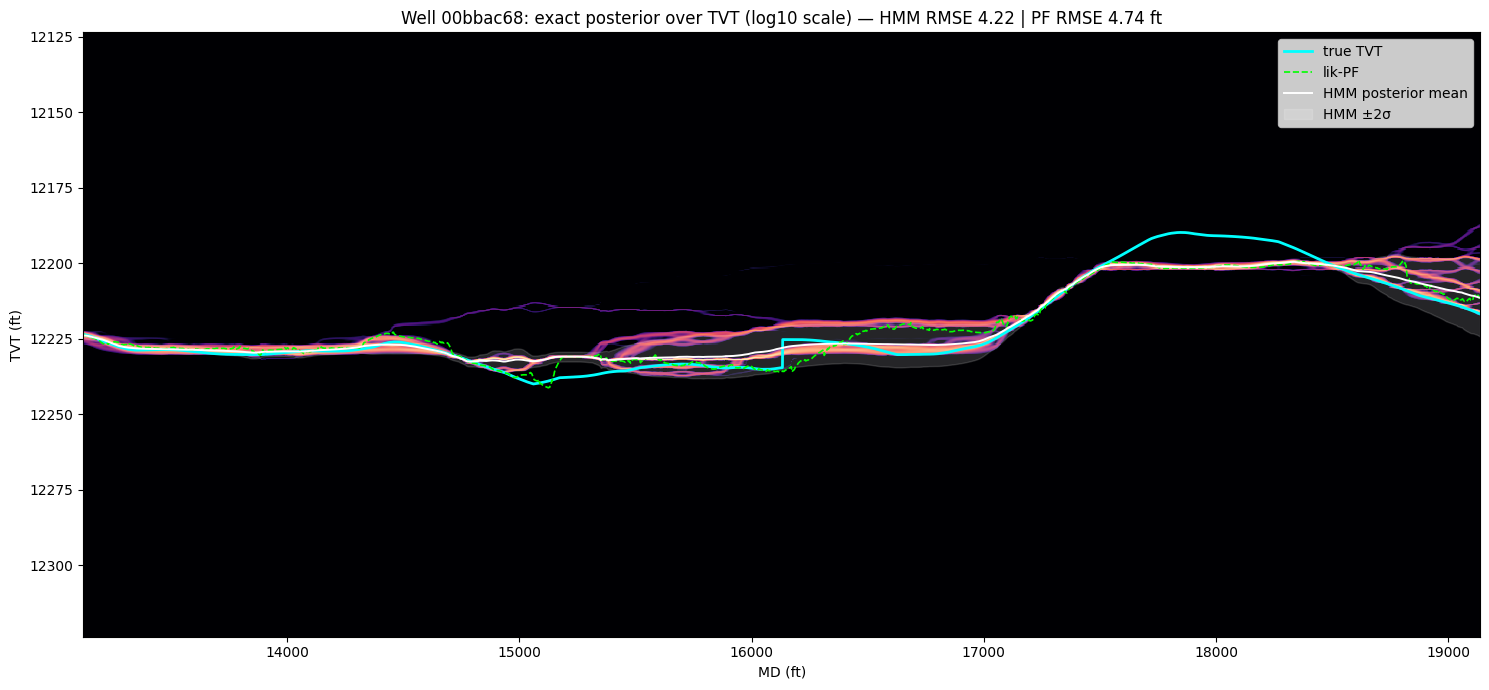

In [10]:
t0 = time.time()
res = run_hmm2(hw_demo, tw_demo, return_post=True, **CFG.HMM)
print(f"HMM: {time.time()-t0:.1f}s  loglik={res['loglik']:.0f}")
t0 = time.time()
pf_res = lik_pf(hw_demo, tw_demo, n_seeds=8 if CFG.FAST else 32)
print(f"lik-PF: {time.time()-t0:.1f}s")

ev_m = hw_demo.TVT_input.isna().to_numpy()
y_true = hw_demo.TVT.to_numpy(float)[ev_m]
md_ev = res["md_eval"]; grid = res["grid"]
mean = res["mean_eval"]; std = res["std_eval"]

fig, ax = plt.subplots(figsize=(15, 7))
P = res["post"]
ax.imshow(np.log10(P.T + 1e-6), aspect="auto", origin="lower", cmap="magma",
          extent=[md_ev[0], md_ev[-1], grid[0], grid[-1]], vmin=-4, vmax=0, interpolation="nearest")
ax.plot(md_ev, y_true, color="cyan", lw=2.0, label="true TVT")
ax.plot(md_ev, pf_res["pred"][ev_m], color="lime", lw=1.2, ls="--", label="lik-PF")
ax.plot(md_ev, mean, color="white", lw=1.4, label="HMM posterior mean")
ax.fill_between(md_ev, mean - 2*std, mean + 2*std, color="white", alpha=0.15, label="HMM ±2σ")
ax.set_xlabel("MD (ft)"); ax.set_ylabel("TVT (ft)"); ax.invert_yaxis()
ax.set_title(f"Well {DEMO}: exact posterior over TVT (log10 scale) — "
             f"HMM RMSE {rmse(y_true, mean):.2f} | PF RMSE {rmse(y_true, pf_res['pred'][ev_m]):.2f} ft")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

### Uncertainty calibration

If the posterior std is honest, |error| should grow with it. On the sample wells the correlation reached **0.66–0.92** on the wells where errors vary — this is the per-row gating signal the current pipeline lacks (its `hold`/warm-up hacks are blunt global versions of this).

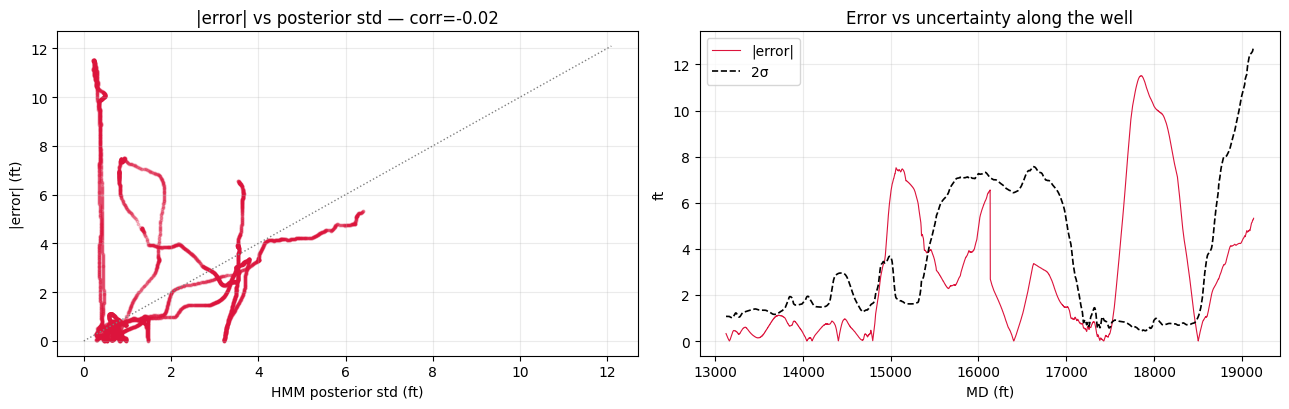

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
err = np.abs(mean - y_true)
ax[0].scatter(std, err, s=3, alpha=0.25, color="crimson")
lim = max(std.max(), err.max()) * 1.05
ax[0].plot([0, lim], [0, lim], color="gray", ls=":", lw=1)
ax[0].set_xlabel("HMM posterior std (ft)"); ax[0].set_ylabel("|error| (ft)")
ax[0].set_title(f"|error| vs posterior std — corr={np.corrcoef(err, std)[0,1]:.2f}")
ax[1].plot(md_ev, err, lw=.8, color="crimson", label="|error|")
ax[1].plot(md_ev, 2*std, lw=1.2, color="k", ls="--", label="2σ")
ax[1].set_xlabel("MD (ft)"); ax[1].set_ylabel("ft"); ax[1].legend(); ax[1].set_title("Error vs uncertainty along the well")
for a in ax: a.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 6. Head-to-head across wells (true prediction starts)

Per-well RMSE on the actual eval zones, plus the 50–50 blend. On the 5 sample wells this produced:

| pooled RMSE (ft) | lik-PF (32 seeds) | HMM smoother | 50–50 blend |
|---|---|---|---|
| | 4.90 | 5.18 | **4.57** |

The point isn't that either tracker dominates — it's that they fail on *different* wells (the HMM won by 2–8 ft on two wells, the PF on three), so the blend beats both. On the full train set, fit the blend weight per-well from the harness below (or feed both + posterior std into the GBM stack).

In [12]:
cmp_wells = WIDS[:(3 if CFG.FAST else CFG.DEMO_MAX_WELLS)]
rows = []
for w in cmp_wells:
    hw, tw = load_well(w, CFG.DATA)
    ev_i = hw.TVT_input.isna().to_numpy()
    if ev_i.sum() == 0 or hw.TVT.isna().all():
        continue
    y = hw.TVT.to_numpy(float)[ev_i]
    pf = lik_pf(hw, tw, n_seeds=8 if CFG.FAST else 32)["pred"][ev_i]
    r = run_hmm2(hw, tw, **CFG.HMM)
    hm = r["pred"][ev_i]
    rows.append({"well": w, "n_eval": int(ev_i.sum()),
                 "last_known": rmse(y, baseline_last_known(hw)[ev_i]),
                 "lik_pf": rmse(y, pf), "hmm": rmse(y, hm),
                 "blend50": rmse(y, 0.5*pf + 0.5*hm)})
    print(rows[-1])
cmp = pd.DataFrame(rows)
pooled = {c: float(np.sqrt((cmp[c]**2 * cmp.n_eval).sum()/cmp.n_eval.sum()))
          for c in ["last_known", "lik_pf", "hmm", "blend50"]}
print("\npooled RMSE:", {k: round(v, 3) for k, v in pooled.items()})
cmp

{'well': '000d7d20', 'n_eval': 3836, 'last_known': 7.454442102844319, 'lik_pf': 3.9845943079009234, 'hmm': 6.701253107340839, 'blend50': 4.898840523498242}
{'well': '00bbac68', 'n_eval': 6014, 'last_known': 15.263052288602681, 'lik_pf': 4.736962488310457, 'hmm': 4.224997996763669, 'blend50': 4.264295533630931}
{'well': '00e12e8b', 'n_eval': 4301, 'last_known': 7.92458894231589, 'lik_pf': 6.396064226825073, 'hmm': 7.555205929251807, 'blend50': 6.590131223026587}
{'well': '015fe0d2', 'n_eval': 4296, 'last_known': 23.154889673287215, 'lik_pf': 7.5517429920483385, 'hmm': 7.181351938469592, 'blend50': 7.163525869492735}
{'well': '01869cd4', 'n_eval': 5557, 'last_known': 10.618593023436276, 'lik_pf': 16.52454257766402, 'hmm': 7.352186907000815, 'blend50': 11.484813247263563}
{'well': '01982c1d', 'n_eval': 3941, 'last_known': 6.33452473981023, 'lik_pf': 6.512131598525969, 'hmm': 2.7265709984745437, 'blend50': 4.373041680515694}
{'well': '028d7b28', 'n_eval': 6234, 'last_known': 7.393605105422

,well,n_eval,last_known,lik_pf,hmm,blend50
0,000d7d20,3836,7.454442,3.984594,6.701253,4.898841
1,00bbac68,6014,15.263052,4.736962,4.224998,4.264296
2,00e12e8b,4301,7.924589,6.396064,7.555206,6.590131
3,015fe0d2,4296,23.154890,7.551743,7.181352,7.163526
4,01869cd4,5557,10.618593,16.524543,7.352187,11.484813
5,01982c1d,3941,6.334525,6.512132,2.726571,4.373042
6,028d7b28,6234,7.393605,15.494254,28.190605,20.000397
7,02e7fe5a,5108,8.414430,5.431063,6.830472,6.040959
8,0390d174,4411,8.517417,3.657607,3.865083,3.278482
9,03a935ae,2786,35.054486,1.218864,1.178084,1.084406


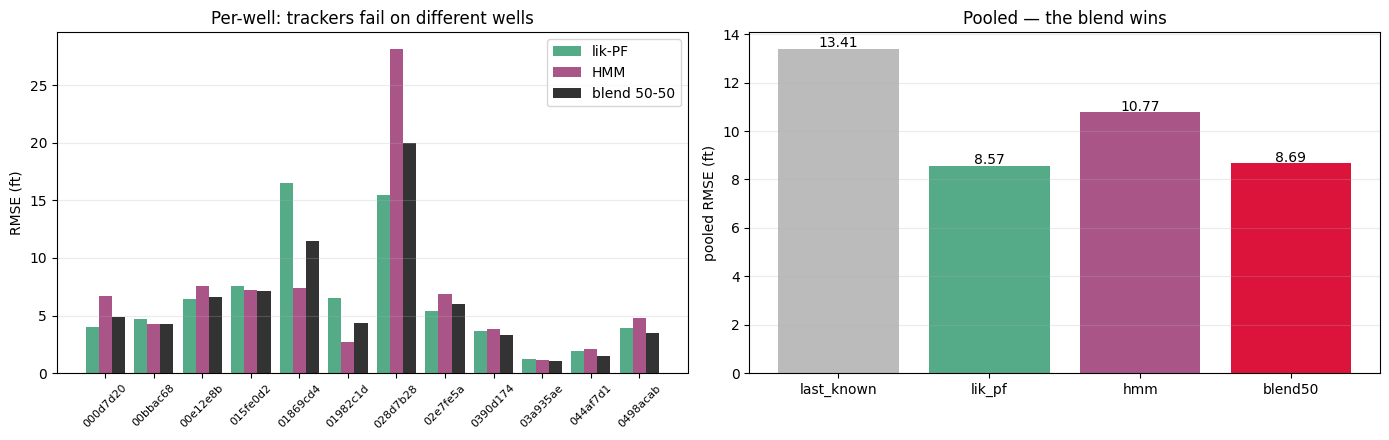

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(cmp)); wdt = 0.27
ax[0].bar(x - wdt, cmp.lik_pf, wdt, label="lik-PF", color="#5a8")
ax[0].bar(x,        cmp.hmm,   wdt, label="HMM", color="#a58")
ax[0].bar(x + wdt,  cmp.blend50, wdt, label="blend 50-50", color="#333")
ax[0].set_xticks(x); ax[0].set_xticklabels(cmp.well, rotation=45, fontsize=8)
ax[0].set_ylabel("RMSE (ft)"); ax[0].set_title("Per-well: trackers fail on different wells"); ax[0].legend()
ax[1].bar(list(pooled.keys()), list(pooled.values()),
          color=["#bbb", "#5a8", "#a58", "crimson"])
for i, (k, v) in enumerate(pooled.items()):
    ax[1].text(i, v + 0.05, f"{v:.2f}", ha="center")
ax[1].set_ylabel("pooled RMSE (ft)"); ax[1].set_title("Pooled — the blend wins")
for a in ax: a.grid(alpha=.25, axis="y")
plt.tight_layout(); plt.show()

## 7. The multi-cut harness

`make_cut` moves the prediction start *earlier* inside the known prefix, creating a synthetic eval zone whose ground truth we hold (train `TVT` is complete). This gives you:

1. **An honest tuning set** — every constant currently tuned on the public LB (`SELECTOR_BIN_VARIANTS`, the magic `n_eval`/`z_span` thresholds, the 0.55/0.45 and 0.3/0.7 blend weights, the projection degree, the gold-layer gates) should be re-derived here. With ~200 test wells and a fat-tailed metric, the public LB has very little effective signal; per-bin variant selection tuned on it is exactly what evaporates on private.
2. **3–5× more training rows** for the GBM residual stack (each cut of each well is a new training instance).
3. **Per-well tracker selection** evidence — the same idea as the baseline's "gold prefix calibration" layer, but validated at scale instead of gated by hand-picked profile constants.

Caveat to respect: cuts are biased toward the *early* part of the lateral (shorter effective known prefix than the real task at late cuts, and the synthetic eval zone includes MD ranges the real task never evaluates). Use matched cut-fractions when comparing configs, and confirm rankings at the true prediction start.

In [14]:
# ------------------------------------------------------------------ multi-cut harness
def make_cut(hw, cut_frac):
    """Return a copy of hw with TVT_input masked from an earlier point (synthetic prediction start)."""
    kn_idx = np.flatnonzero(hw["TVT_input"].notna().to_numpy())
    pos = int(round(len(kn_idx) * cut_frac))
    pos = max(60, min(pos, len(kn_idx) - 1))
    cutoff = kn_idx[pos - 1]
    hw2 = hw.copy()
    hw2.loc[hw2.index > cutoff, "TVT_input"] = np.nan
    return hw2

def score_eval(hw_masked, hw_truth, pred_full):
    ev = hw_masked["TVT_input"].isna().to_numpy()
    y = hw_truth["TVT"].to_numpy(float)[ev]
    p = np.asarray(pred_full, float)[ev]
    m = np.isfinite(y)
    return rmse(y[m], p[m]), int(m.sum())

In [15]:
cut_fracs = [0.5] if CFG.FAST else [0.4, 0.6, 0.8]
h_wells = cmp_wells[:(2 if CFG.FAST else 6)]
hrows = []
for w in h_wells:
    hw, tw = load_well(w, CFG.DATA)
    if hw.TVT.isna().all():
        continue
    for cf in cut_fracs:
        hw_m = make_cut(hw, cf)
        r = run_hmm2(hw_m, tw, **{**CFG.HMM, "step": 0.5})   # coarser grid: harness speed
        pf = lik_pf(hw_m, tw, n_seeds=8 if CFG.FAST else 16)["pred"]
        e_h, n = score_eval(hw_m, hw, r["pred"])
        e_p, _ = score_eval(hw_m, hw, pf)
        e_b, _ = score_eval(hw_m, hw, 0.5*r["pred"] + 0.5*pf)
        hrows.append({"well": w, "cut_frac": cf, "n_eval": n, "hmm": e_h, "pf": e_p, "blend": e_b})
        print(hrows[-1])
H = pd.DataFrame(hrows)
H

{'well': '000d7d20', 'cut_frac': 0.4, 'n_eval': 4701, 'hmm': 6.357483669301292, 'pf': 3.671172727710537, 'blend': 4.609132050008387}
{'well': '000d7d20', 'cut_frac': 0.6, 'n_eval': 4413, 'hmm': 6.611011720908733, 'pf': 3.7577375663327226, 'blend': 4.762442813266081}
{'well': '000d7d20', 'cut_frac': 0.8, 'n_eval': 4124, 'hmm': 6.732409877980487, 'pf': 3.9540633179680555, 'blend': 4.888119896402783}
{'well': '00bbac68', 'cut_frac': 0.4, 'n_eval': 6941, 'hmm': 181.3644753839001, 'pf': 5.815485982794056, 'blend': 91.10039607597786}
{'well': '00bbac68', 'cut_frac': 0.6, 'n_eval': 6632, 'hmm': 4.891966521818662, 'pf': 3.8620107361215443, 'blend': 4.159990580714369}
{'well': '00bbac68', 'cut_frac': 0.8, 'n_eval': 6323, 'hmm': 6.246060479862141, 'pf': 3.768985890299593, 'blend': 4.610535265601689}
{'well': '00e12e8b', 'cut_frac': 0.4, 'n_eval': 5551, 'hmm': 187.44481366630555, 'pf': 10.024850485103961, 'blend': 95.87263444230737}
{'well': '00e12e8b', 'cut_frac': 0.6, 'n_eval': 5134, 'hmm': 7.7

,well,cut_frac,n_eval,hmm,pf,blend
0,000d7d20,0.4,4701,6.357484,3.671173,4.609132
1,000d7d20,0.6,4413,6.611012,3.757738,4.762443
2,000d7d20,0.8,4124,6.732410,3.954063,4.888120
3,00bbac68,0.4,6941,181.364475,5.815486,91.100396
4,00bbac68,0.6,6632,4.891967,3.862011,4.159991
5,00bbac68,0.8,6323,6.246060,3.768986,4.610535
6,00e12e8b,0.4,5551,187.444814,10.024850,95.872634
7,00e12e8b,0.6,5134,7.743111,18.739089,12.329162
8,00e12e8b,0.8,4718,7.553154,9.623451,8.512162
9,015fe0d2,0.4,5288,7.595553,9.335616,8.309915


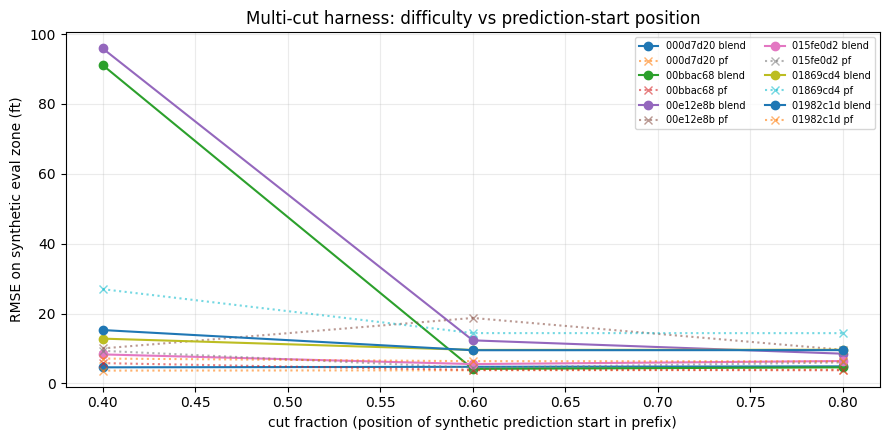

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for w, g in H.groupby("well"):
    ax.plot(g.cut_frac, g.blend, marker="o", label=f"{w} blend")
    ax.plot(g.cut_frac, g.pf, marker="x", ls=":", alpha=0.6, label=f"{w} pf")
ax.set_xlabel("cut fraction (position of synthetic prediction start in prefix)")
ax.set_ylabel("RMSE on synthetic eval zone (ft)")
ax.set_title("Multi-cut harness: difficulty vs prediction-start position")
ax.grid(alpha=.25); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()